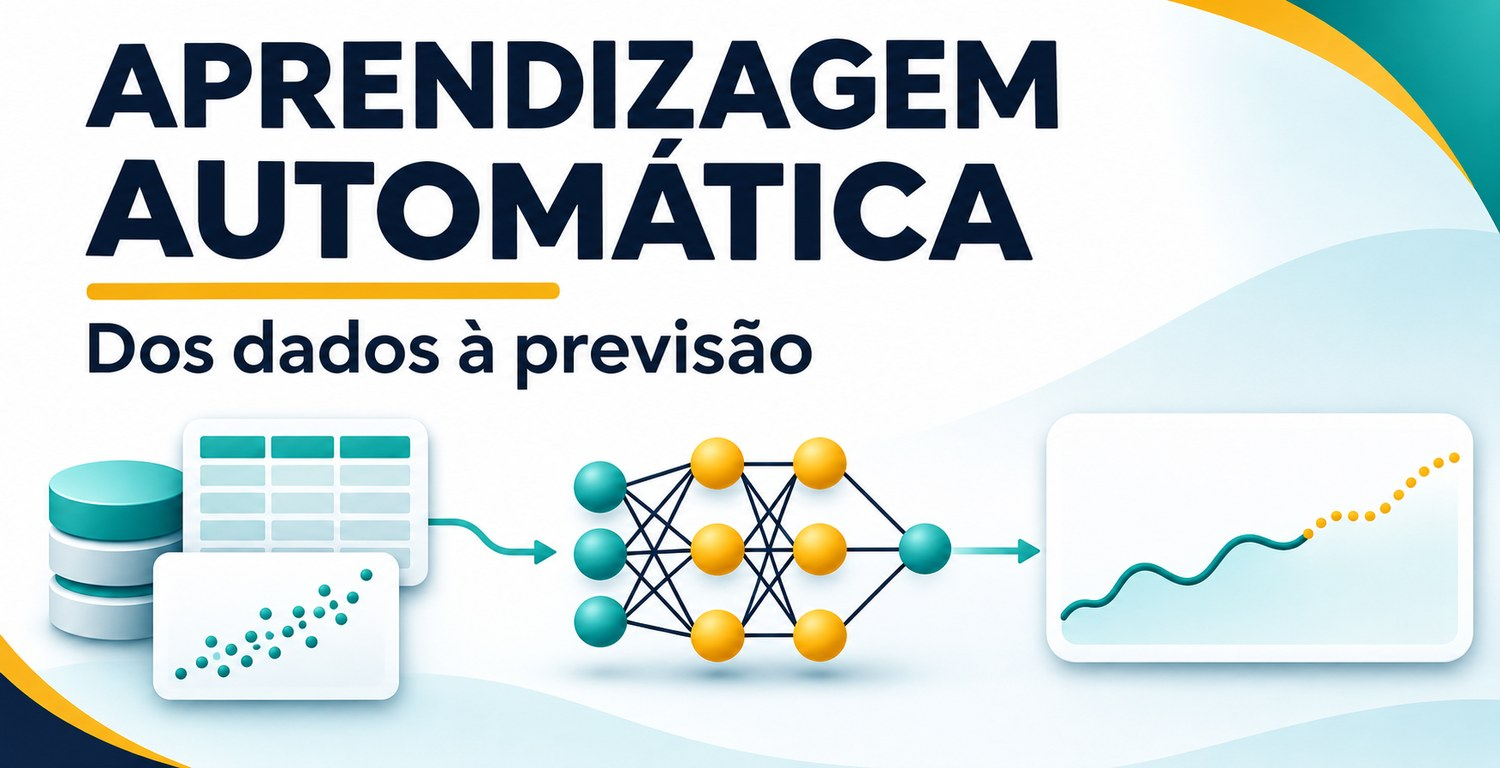

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Aprendizagem%20Autom%C3%A1tica/tutorial_machine_learning/modulo_1_aprender_com_dados/03_Interface_scikit_learn_e_Fluxo.ipynb)

# Capítulo 3 – A interface do scikit-learn e o fluxo de um projeto

Ao longo do tutorial vamos usar dezenas de modelos e de transformações, quase todos do scikit-learn. Todos se usam da mesma maneira, porque a biblioteca assenta num pequeno conjunto de convenções. Quem as conhece lê qualquer exemplo, troca um modelo por outro numa linha e consegue escrever os seus próprios componentes. Este capítulo explica essas convenções, constrói um classificador de raiz que as respeita e termina com o fluxo completo de um projeto, que serve de mapa para os módulos seguintes.

> **Objetivos:** descrever a forma de `X` e de `y`; distinguir estimador, preditor e transformador; distinguir hiperparâmetros de parâmetros aprendidos; escrever um classificador compatível com o scikit-learn e usá-lo em validação cruzada e numa procura em grelha; percorrer as sete etapas de um projeto supervisionado; reconhecer os principais riscos de usar modelos aprendidos.

**Pré-requisitos:** capítulos 1 e 2 deste módulo. O capítulo usa classes; se precisares de rever, vê [Programação orientada a objetos](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/engenharia_software/ES_01_POO_Python.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_lotes(n=900, semente=7):
    """Gera lotes de azeitona entregues num lagar fictício (dados sintéticos; as medições são inventadas)."""
    rng = np.random.default_rng(semente)
    # variedade: peso médio do fruto (g), comprimento (mm), razão comprimento/largura, rendimento de base (%)
    perfis = {"Galega": (2.4, 17.5, 1.42, 15.5), "Cobrançosa": (4.3, 22.0, 1.33, 18.5), "Cordovil": (5.0, 23.0, 1.22, 20.0)}
    variedade = rng.choice(list(perfis), n, p=[0.45, 0.33, 0.22])
    base = np.array([perfis[v] for v in variedade])
    peso = np.clip(rng.normal(base[:, 0], 0.55), 1.0, None)
    comprimento = base[:, 1] + 2.2 * (peso - base[:, 0]) + rng.normal(0, 1.1, n)
    largura = comprimento / base[:, 2] + rng.normal(0, 0.5, n)
    maturacao = np.clip(rng.normal(3.4, 1.2, n), 0, 7)
    humidade = np.clip(rng.normal(52 - 1.5 * (maturacao - 3.4), 4), 38, 66)
    rendimento = base[:, 3] + 1.1 * (maturacao - 3.4) - 0.28 * (humidade - 52) + rng.normal(0, 1.0, n)
    return pd.DataFrame({
        "lote_id": [f"L{i:04d}" for i in range(1, n + 1)],
        "variedade": variedade,
        "peso_g": peso.round(2),
        "comprimento_mm": comprimento.round(1),
        "largura_mm": largura.round(1),
        "maturacao": maturacao.round(1),
        "humidade_pct": humidade.round(1),
        "rendimento_pct": rendimento.round(1),
    })


lotes = gerar_lotes()
print(lotes.shape)
lotes.head()

(900, 8)


,lote_id,variedade,peso_g,comprimento_mm,largura_mm,maturacao,humidade_pct,rendimento_pct
0,L0001,Cobrançosa,4.24,21.3,15.7,3.1,53.2,17.9
1,L0002,Cordovil,5.25,22.5,18.3,6.3,48.3,25.7
2,L0003,Cobrançosa,4.71,23.9,17.5,3.0,52.5,18.3
3,L0004,Galega,2.16,15.8,10.4,2.0,57.2,11.5
4,L0005,Galega,2.57,15.5,10.2,3.4,44.4,17.0


## Como o scikit-learn vê os dados

Todos os modelos esperam os dados na mesma forma:

- **`X`** é uma tabela com duas dimensões: uma **linha por exemplo** e uma **coluna por atributo**. A sua forma é `(n_exemplos, n_atributos)`. Pode ser um `DataFrame` ou uma matriz do NumPy.
- **`y`** é um vetor com uma dimensão: um valor por exemplo, na mesma ordem das linhas de `X`. Em classificação pode conter texto; não é preciso converter as classes em números.

X: DataFrame (900, 3) → 900 exemplos e 3 atributos
y: Series (900,) → classes: ['Cobrançosa', 'Cordovil', 'Galega']


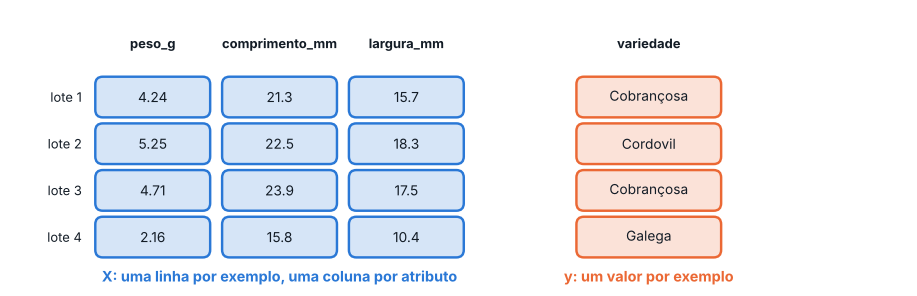

In [3]:
frutos = ["peso_g", "comprimento_mm", "largura_mm"]
X = lotes[frutos]
y = lotes["variedade"]
print("X:", type(X).__name__, X.shape, "→", X.shape[0], "exemplos e", X.shape[1], "atributos")
print("y:", type(y).__name__, y.shape, "→ classes:", sorted(y.unique()))

fig, ax = tela(12, 3.6, (10.5, 3.2))
for j, nome in enumerate(frutos):
    ax.text(1.9 + j * 1.7, 3.1, nome, ha="center", fontsize=8.5, color=TINTA, fontweight="bold")
    for i in range(4):
        caixa(ax, 1.15 + j * 1.7, 2.2 - i * 0.62, 1.5, 0.5, str(X.iloc[i, j]), AZUL, 9)
for i in range(4):
    ax.text(0.95, 2.45 - i * 0.62, f"lote {i + 1}", ha="right", va="center", fontsize=8.5, color=TINTA)
    caixa(ax, 7.6, 2.2 - i * 0.62, 1.9, 0.5, y.iloc[i], LARANJA, 9)
ax.text(8.55, 3.1, "variedade", ha="center", fontsize=8.5, color=TINTA, fontweight="bold")
ax.text(3.6, 0.0, "X: uma linha por exemplo, uma coluna por atributo", ha="center", color=AZUL, fontsize=9.5, fontweight="bold")
ax.text(8.55, 0.0, "y: um valor por exemplo", ha="center", color=LARANJA, fontsize=9.5, fontweight="bold")
plt.show()

O erro mais frequente de quem começa é passar um só atributo como vetor. `lotes["peso_g"]` tem forma `(900,)`, e o scikit-learn não sabe se são 900 exemplos de um atributo ou um exemplo com 900 atributos. Com parênteses retos duplos, `lotes[["peso_g"]]`, obtém-se uma tabela de forma `(900, 1)`.

In [4]:
print("Uma coluna como vetor: ", lotes["peso_g"].shape)
print("Uma coluna como tabela:", lotes[["peso_g"]].shape)

Uma coluna como vetor:  (900,)
Uma coluna como tabela: (900, 1)


## Três papéis, sempre os mesmos métodos

Qualquer objeto do scikit-learn que aprende com dados é um **estimador**: tem um método `fit`. Conforme o que faz depois de aprender, é também um preditor, um transformador, ou ambos.

| Papel | Métodos | O que faz | Exemplos |
| --- | --- | --- | --- |
| **Estimador** | `fit(X, y)` ou `fit(X)` | aprende com os dados e devolve-se a si próprio | todos |
| **Preditor** | `predict(X)`, `score(X, y)`; nos classificadores, também `predict_proba(X)` | devolve uma previsão para cada linha | `LogisticRegression`, `KNeighborsClassifier` |
| **Transformador** | `transform(X)`, `fit_transform(X)` | devolve uma nova versão de `X` | `StandardScaler`, `OneHotEncoder`, `PCA` |

Um `Pipeline` é ele próprio um estimador: encadeia transformadores e termina, em geral, num preditor.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

escala = StandardScaler()                         # um transformador
escala.fit(X_treino)                              # aprende a média e o desvio padrão de cada coluna
X_treino_escalado = escala.transform(X_treino)    # aplica o que aprendeu
X_teste_escalado = escala.transform(X_teste)      # no teste, só aplica: não volta a aprender

modelo = LogisticRegression(C=100)                # um preditor
modelo.fit(X_treino_escalado, y_treino)
print("Previsões:     ", modelo.predict(X_teste_escalado[:4]))
print("Probabilidades:", modelo.predict_proba(X_teste_escalado[:1]).round(3), "na ordem", modelo.classes_)
print("Exatidão no teste (score):", round(modelo.score(X_teste_escalado, y_teste), 3))

Previsões:      ['Cordovil' 'Cordovil' 'Cobrançosa' 'Cordovil']
Probabilidades: [[0.146 0.854 0.   ]] na ordem ['Cobrançosa' 'Cordovil' 'Galega']
Exatidão no teste (score): 0.947


Repara que `fit` foi chamado só com o treino, e que no teste se usou `transform`. Chamar `fit_transform` no teste seria uma fuga de informação (capítulo 1, parte 3).

## Hiperparâmetros e parâmetros aprendidos

Há dois tipos de valores dentro de um estimador, e o scikit-learn distingue-os pelo nome:

- os **hiperparâmetros** são escolhidos por nós, **antes** de treinar, ao criar o objeto. Consultam-se com `get_params()`;
- os **parâmetros aprendidos** são calculados pelo `fit`. O nome termina sempre com um **traço inferior**: `mean_`, `coef_`, `classes_`.

In [6]:
print("Hiperparâmetros do modelo (alguns):", {k: v for k, v in modelo.get_params().items() if k in ["C", "max_iter", "fit_intercept"]})
print("\nAprendido pela escala:")
print("  mean_ :", escala.mean_.round(2))
print("  scale_:", escala.scale_.round(2))
print("\nAprendido pelo modelo:")
print("  classes_  :", modelo.classes_)
print("  coef_     : forma", modelo.coef_.shape, "(uma linha por classe, uma coluna por atributo)")
print("  intercept_:", modelo.intercept_.round(2))

Hiperparâmetros do modelo (alguns): {'C': 100, 'fit_intercept': True, 'max_iter': 100}

Aprendido pela escala:
  mean_ : [ 3.57 20.15 15.08]
  scale_: [1.28 3.07 3.1 ]

Aprendido pelo modelo:
  classes_  : ['Cobrançosa' 'Cordovil' 'Galega']
  coef_     : forma (3, 3) (uma linha por classe, uma coluna por atributo)
  intercept_: [ 3.63 -3.89  0.26]


A regra do traço inferior é útil na prática: se `modelo.coef_` der erro, o modelo ainda não foi treinado.

In [7]:
novo = LogisticRegression()
try:
    novo.coef_          # ⚠️ erro de propósito: ainda não houve fit
except AttributeError as erro:
    print("AttributeError:", erro)

AttributeError: 'LogisticRegression' object has no attribute 'coef_'


## A mesma interface para todos os modelos

Como todos os preditores têm `fit`, `predict` e `score`, trocar de modelo é mudar uma linha. O código à volta não muda.

In [8]:
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

modelos = {"Regressão logística": LogisticRegression(C=100),
           "KNN (k = 5)": KNeighborsClassifier(n_neighbors=5),
           "Árvore (profundidade 4)": DecisionTreeClassifier(max_depth=4, random_state=0),
           "Naive Bayes": GaussianNB()}

for nome, m in modelos.items():
    pipeline = Pipeline([("escala", StandardScaler()), ("modelo", m)])
    exatidao = cross_val_score(pipeline, X_treino, y_treino, cv=5)
    print(f"{nome:<25} {exatidao.mean():.3f} ± {exatidao.std():.3f}")

Regressão logística       0.960 ± 0.008
KNN (k = 5)               0.929 ± 0.022
Árvore (profundidade 4)   0.889 ± 0.027


Naive Bayes               0.843 ± 0.027


Os quatro modelos funcionam de formas muito diferentes por dentro, e são tratados nos módulos 3, 5, 6 e 7. Aqui interessa que o ciclo não precisou de saber nada sobre cada um.

## Escrever um estimador de raiz

A melhor forma de perceber a interface é implementá-la. Vamos escrever um classificador muito simples, conhecido por **1R** («uma regra»):

1. para cada atributo, divide os valores em alguns intervalos;
2. em cada intervalo, prevê a classe mais frequente nesse intervalo;
3. fica com o **único atributo** que acerta mais vezes nos dados de treino.

O resultado é uma regra que qualquer pessoa aplica de cabeça, como «se a largura do fruto for inferior a 15 mm, é Galega». Em 1993, Robert Holte mostrou que regras deste tipo ficavam surpreendentemente perto de modelos muito mais complexos em vários conjuntos de dados usados na altura. É uma linha de base mais exigente do que a classe mais frequente.

Para ser compatível com o scikit-learn, a classe tem de cumprir quatro convenções:

- herdar de `BaseEstimator` (que fornece `get_params` e `set_params`) e de `ClassifierMixin` (que fornece `score`);
- o `__init__` só **guarda** os hiperparâmetros, com o mesmo nome dos argumentos, e não faz mais nada;
- o `fit` guarda o que aprendeu em atributos com traço inferior e termina com `return self`;
- o `predict` devolve um vetor com uma previsão por linha.

In [9]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_is_fitted


class UmaRegra(ClassifierMixin, BaseEstimator):
    """Classificador 1R: escolhe um atributo, divide-o em intervalos e prevê a classe mais frequente de cada um."""

    def __init__(self, n_intervalos=4):
        self.n_intervalos = n_intervalos                          # hiperparâmetro: só se guarda

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        self.classes_ = np.unique(y)
        self.n_features_in_ = X.shape[1]
        melhor_exatidao = -1.0
        for j in range(X.shape[1]):
            # limites que dividem o atributo j em intervalos com o mesmo número de exemplos
            limites = np.quantile(X[:, j], np.linspace(0, 1, self.n_intervalos + 1)[1:-1])
            intervalo = np.searchsorted(limites, X[:, j])         # em que intervalo cai cada exemplo
            classe = np.array([self._mais_frequente(y[intervalo == i], y) for i in range(self.n_intervalos)])
            exatidao = np.mean(classe[intervalo] == y)
            if exatidao > melhor_exatidao:
                melhor_exatidao = exatidao
                self.atributo_, self.limites_, self.classe_por_intervalo_ = j, limites, classe
        self.exatidao_treino_ = melhor_exatidao
        return self

    @staticmethod
    def _mais_frequente(y_intervalo, y_todos):
        """Classe mais frequente num intervalo (se o intervalo estiver vazio, usa todos os exemplos)."""
        valores, contagens = np.unique(y_intervalo if len(y_intervalo) else y_todos, return_counts=True)
        return valores[contagens.argmax()]

    def predict(self, X):
        check_is_fitted(self)                                     # dá um erro claro se ainda não houve fit
        X = np.asarray(X, dtype=float)
        return self.classe_por_intervalo_[np.searchsorted(self.limites_, X[:, self.atributo_])]


regra = UmaRegra(n_intervalos=4).fit(X_treino, y_treino)
print("Atributo escolhido:", frutos[regra.atributo_])
print("Limites dos intervalos:", regra.limites_.round(2))
print("Classe prevista em cada intervalo:", regra.classe_por_intervalo_.tolist())
print(f"Exatidão no treino: {regra.exatidao_treino_:.3f} | no teste: {regra.score(X_teste, y_teste):.3f}")

Atributo escolhido: largura_mm
Limites dos intervalos: [12.3 15.1 17.5]
Classe prevista em cada intervalo: ['Galega', 'Galega', 'Cobrançosa', 'Cordovil']
Exatidão no treino: 0.841 | no teste: 0.844


A regra aprendida lê-se diretamente dos atributos com traço inferior. O método `score` não foi escrito por nós: veio do `ClassifierMixin`, que o calcula a partir do `predict`.

### O que se ganha por respeitar a interface

Como `UmaRegra` cumpre as convenções, funciona com todas as ferramentas da biblioteca sem mais código: validação cruzada, *pipelines* e procura de hiperparâmetros.

In [10]:
from sklearn.model_selection import GridSearchCV

print("Hiperparâmetros:", regra.get_params())
print("Validação cruzada:", cross_val_score(UmaRegra(), X_treino, y_treino, cv=5).round(3))

procura = GridSearchCV(UmaRegra(), {"n_intervalos": [2, 3, 4, 5, 6, 8, 10]}, cv=5).fit(X_treino, y_treino)
tabela = pd.DataFrame(procura.cv_results_)[["param_n_intervalos", "mean_test_score", "std_test_score"]].round(3)
print(tabela.to_string(index=False))
print("\nMelhor número de intervalos:", procura.best_params_["n_intervalos"], "| atributo escolhido:", frutos[procura.best_estimator_.atributo_])

Hiperparâmetros: {'n_intervalos': 4}
Validação cruzada: [0.807 0.822 0.874 0.881 0.815]


 param_n_intervalos  mean_test_score  std_test_score
                  2            0.742           0.030
                  3            0.719           0.056
                  4            0.840           0.031
                  5            0.831           0.035
                  6            0.850           0.022
                  8            0.844           0.031
                 10            0.852           0.024

Melhor número de intervalos: 10 | atributo escolhido: largura_mm


A procura escolhe 10 intervalos, mas lê a tabela inteira: de 4 intervalos em diante, as diferenças são menores do que o desvio padrão entre partes. O `GridSearchCV` devolve sempre o máximo, mesmo quando o máximo não se distingue dos vizinhos. Entre regras equivalentes, a de 4 intervalos é a mais fácil de ler.

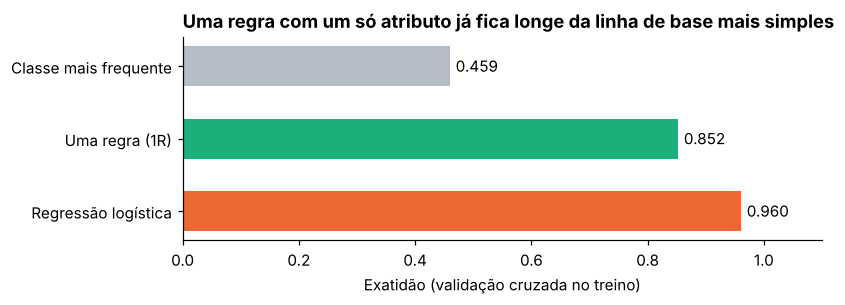

In [11]:
comparar = {"Classe mais frequente": y_treino.value_counts(normalize=True).max(),
            "Uma regra (1R)": procura.best_score_,
            "Regressão logística": cross_val_score(Pipeline([("escala", StandardScaler()), ("modelo", LogisticRegression(C=100))]),
                                                   X_treino, y_treino, cv=5).mean()}
fig, ax = plt.subplots(figsize=(7.5, 2.4))
barras = ax.barh(list(comparar), list(comparar.values()), color=[CINZA, VERDE, LARANJA], height=0.55)
ax.bar_label(barras, fmt="%.3f", padding=4)
ax.set_xlim(0, 1.1)
ax.invert_yaxis()
ax.set_xlabel("Exatidão (validação cruzada no treino)")
ax.set_title("Uma regra com um só atributo já fica longe da linha de base mais simples")
plt.show()

Com um único atributo, a regra recupera grande parte da distância entre a classe mais frequente e a regressão logística. O que lhe falta é o que os três atributos em conjunto conseguem: separar a Cobrançosa da Cordovil pela forma do fruto.

## O fluxo de um projeto supervisionado

Um projeto percorre sempre as mesmas etapas. O esquema indica os módulos deste tutorial que tratam cada uma.

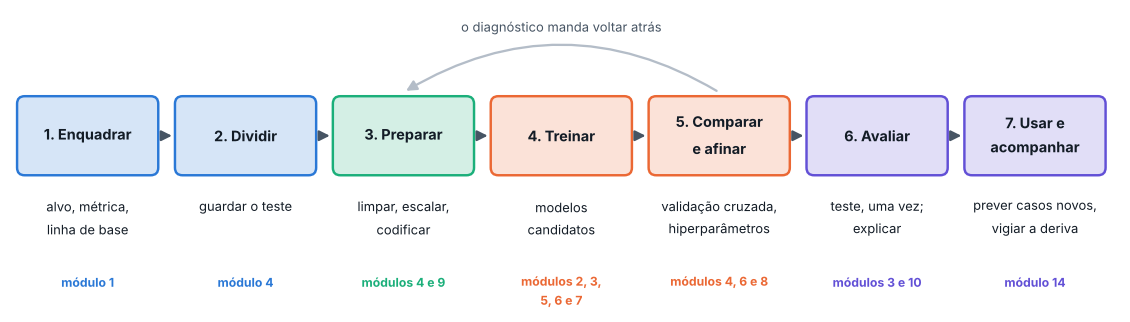

In [12]:
etapas = [("1. Enquadrar", "alvo, métrica,\nlinha de base", "módulo 1", AZUL),
          ("2. Dividir", "guardar o teste", "módulo 4", AZUL),
          ("3. Preparar", "limpar, escalar,\ncodificar", "módulos 4 e 9", VERDE),
          ("4. Treinar", "modelos\ncandidatos", "módulos 2, 3,\n5, 6 e 7", LARANJA),
          ("5. Comparar\ne afinar", "validação cruzada,\nhiperparâmetros", "módulos 4, 6 e 8", LARANJA),
          ("6. Avaliar", "teste, uma vez;\nexplicar", "módulos 3 e 10", VIOLETA),
          ("7. Usar e\nacompanhar", "prever casos novos,\nvigiar a deriva", "módulo 14", VIOLETA)]
fig, ax = tela(14.6, 3.9, (13, 3.5))
for i, (titulo, texto, onde, cor) in enumerate(etapas):
    x = 0.1 + i * 2.08
    caixa(ax, x, 1.75, 1.82, 1.0, titulo, cor, 9.5, True)
    ax.text(x + 0.91, 1.45, texto, ha="center", va="top", fontsize=8.5, color=TINTA, linespacing=1.4)
    ax.text(x + 0.91, 0.45, onde, ha="center", va="top", fontsize=8, color=cor, fontweight="bold", linespacing=1.3)
    if i < len(etapas) - 1:
        seta(ax, (x + 1.86, 2.25), (x + 2.06, 2.25))
seta(ax, (8.42 + 0.91, 2.82), (4.26 + 0.91, 2.82), cor=CINZA, connectionstyle="arc3,rad=0.3")       # da etapa 5 para a 3
ax.text(7.25, 3.62, "o diagnóstico manda voltar atrás", ha="center", fontsize=8.5, color="#465463")
plt.show()

Vamos percorrer as sete etapas, de forma breve, com o problema de confirmar a variedade.

**1. Enquadrar.** O alvo é a variedade; os atributos são as medições feitas à chegada. Os dois erros (trocar uma variedade por outra) custam o mesmo, e as classes não são muito desequilibradas, por isso a métrica é a exatidão. A linha de base é a classe mais frequente.

**2. Dividir.** Separa-se o teste e não se volta a olhar para ele até à etapa 6.

In [13]:
medicoes = ["peso_g", "comprimento_mm", "largura_mm", "maturacao", "humidade_pct"]
Xp_treino, Xp_teste, yp_treino, yp_teste = train_test_split(lotes[medicoes], lotes["variedade"], test_size=0.25,
                                                            random_state=42, stratify=lotes["variedade"])
linha_de_base = yp_treino.value_counts(normalize=True).max()
print(f"Treino: {len(Xp_treino)} lotes | teste: {len(Xp_teste)} lotes | linha de base: {linha_de_base:.3f}")

Treino: 675 lotes | teste: 225 lotes | linha de base: 0.459


**3, 4 e 5. Preparar, treinar, comparar e afinar.** A preparação e o modelo vão no mesmo `Pipeline`, e o `GridSearchCV` compara os candidatos por validação cruzada, só com o treino. O nome de cada hiperparâmetro na grelha é o nome do passo, dois traços inferiores e o nome do hiperparâmetro (`modelo__C`).

In [14]:
candidatos = {
    "Regressão logística": (LogisticRegression(max_iter=1000), {"modelo__C": [0.1, 1, 10, 100, 1000]}),
    "KNN": (KNeighborsClassifier(), {"modelo__n_neighbors": [3, 7, 15, 31, 61, 121]}),
    "Árvore de decisão": (DecisionTreeClassifier(random_state=0), {"modelo__max_depth": [2, 3, 5, 8, 12]}),
}
procuras = {}
for nome, (m, grelha) in candidatos.items():
    pipeline = Pipeline([("escala", StandardScaler()), ("modelo", m)])
    procuras[nome] = GridSearchCV(pipeline, grelha, cv=5).fit(Xp_treino, yp_treino)
    print(f"{nome:<20} validação cruzada: {procuras[nome].best_score_:.3f} | melhor: {procuras[nome].best_params_}")

escolhido = max(procuras, key=lambda nome: procuras[nome].best_score_)
print("\nModelo escolhido:", escolhido)

Regressão logística  validação cruzada: 0.957 | melhor: {'modelo__C': 100}


KNN                  validação cruzada: 0.864 | melhor: {'modelo__n_neighbors': 31}
Árvore de decisão    validação cruzada: 0.898 | melhor: {'modelo__max_depth': 8}

Modelo escolhido: Regressão logística


O KNN fica bem abaixo da regressão logística, e abaixo do que conseguiu no capítulo 1 só com as medições dos frutos. A razão está nos atributos: a maturação e a humidade nada dizem sobre a variedade, e na distância pesam tanto como os outros três. A regressão logística aprende a dar-lhes um peso quase nulo; o KNN não tem como. Este diagnóstico é o que a seta do esquema representa: mandaria voltar à etapa 3 e rever os atributos. O módulo 5 trata do assunto.

**6. Avaliar.** O modelo escolhido é avaliado no teste, uma única vez. O `GridSearchCV` já o voltou a treinar com todo o treino.

In [15]:
from sklearn.metrics import classification_report

final = procuras[escolhido].best_estimator_
print(f"Exatidão no teste: {final.score(Xp_teste, yp_teste):.3f} (linha de base: {linha_de_base:.3f})\n")
print(classification_report(yp_teste, final.predict(Xp_teste), digits=3))

Exatidão no teste: 0.947 (linha de base: 0.459)

              precision    recall  f1-score   support

  Cobrançosa      0.872     0.987     0.926        76
    Cordovil      0.975     0.848     0.907        46
      Galega      1.000     0.961     0.980       103

    accuracy                          0.947       225
   macro avg      0.949     0.932     0.938       225
weighted avg      0.952     0.947     0.947       225



O relatório mostra a precisão e a sensibilidade de cada variedade. A Galega quase não tem erros; as trocas acontecem entre a Cobrançosa e a Cordovil.

**7. Usar e acompanhar.** O `Pipeline` treinado recebe um lote novo com as medições em bruto e trata de tudo: aplica a escala aprendida no treino e depois o modelo.

In [16]:
lote_novo = pd.DataFrame([{"peso_g": 4.6, "comprimento_mm": 22.4, "largura_mm": 17.6, "maturacao": 3.8, "humidade_pct": 51.0}])
print("Variedade prevista:", final.predict(lote_novo)[0])
print("Probabilidades:", dict(zip(final.classes_, final.predict_proba(lote_novo)[0].round(3).tolist())))

Variedade prevista: Cobrançosa
Probabilidades: {'Cobrançosa': 0.745, 'Cordovil': 0.255, 'Galega': 0.0}


A probabilidade é tão importante como a classe: um lote com 0,55 para uma variedade e 0,44 para outra merece ser visto por uma pessoa, e um lote com 0,99 não.

Depois de entrar em uso, o modelo tem de ser acompanhado. Se o lagar passar a receber uma variedade nova, ou se um ano de seca alterar o tamanho dos frutos, os dados deixam de se parecer com os de treino e o desempenho degrada-se sem aviso. É o tema do módulo 14.

## Os riscos de usar modelos aprendidos

Um modelo aprende o que está nos dados, incluindo o que lá não devia estar. Quatro riscos acompanham qualquer projeto:

| Risco | O que pode correr mal | Onde é tratado |
| --- | --- | --- |
| **Enviesamento e equidade** | os dados representam mal um grupo, ou registam decisões passadas injustas, e o modelo repete-as | [Equidade](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_8_comunicar_e_usar_com_responsabilidade/05_Equidade.ipynb) |
| **Privacidade e segurança** | os dados de treino contêm informação pessoal, que pode ser exposta ou reidentificada | [Privacidade e dados pessoais](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_8_comunicar_e_usar_com_responsabilidade/06_Privacidade_e_Dados_Pessoais.ipynb) |
| **Falta de explicação** | ninguém consegue dizer porque o modelo decidiu assim, o que impede corrigir erros e justificar decisões | módulo 10 deste tutorial |
| **Automatização sem supervisão** | decisões que tinham uma pessoa atenta passam a ser tomadas em série, e os erros também | [Documentar e acompanhar um modelo](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_8_comunicar_e_usar_com_responsabilidade/04_Documentar_e_Acompanhar_um_Modelo.ipynb) |

No lagar, o risco mais concreto é o primeiro: se quase todos os lotes de treino vierem de dois ou três grandes produtores, o modelo aprende as azeitonas desses produtores, e pode errar mais nos lotes dos pequenos, que são precisamente os que têm menos meios para contestar uma classificação.

## Resumo do módulo

- A aprendizagem automática é a parte da inteligência artificial em que as regras são ajustadas a partir de exemplos. A aprendizagem profunda é uma parte dela, com vantagem em imagem, som e texto.
- O tipo de aprendizagem depende da informação disponível: respostas certas (supervisionada), só atributos (não supervisionada) ou recompensas pelas ações escolhidas (por reforço).
- No scikit-learn, tudo o que aprende tem `fit`; os preditores têm `predict` e os transformadores têm `transform`. Os hiperparâmetros definem-se ao criar o objeto, e o que é aprendido termina com traço inferior.
- Um projeto segue sete etapas, e o teste só entra na sexta.
- Um resultado só tem significado ao lado de uma linha de base e de uma comparação justa entre modelos.

## Exercícios

### `Exercício 1` – Hiperparâmetro ou parâmetro aprendido?

Classifica cada valor e diz em que momento é fixado.

1. O número de vizinhos de um KNN.
2. Os coeficientes de uma regressão linear.
3. A profundidade máxima de uma árvore de decisão.
4. A média de cada coluna, num `StandardScaler`.
5. O limiar de cada pergunta de uma árvore de decisão.
6. O valor de ε na estratégia ε-gulosa do capítulo 2.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. **Hiperparâmetro** (`n_neighbors`): escolhe-se antes de treinar.
2. **Aprendidos** (`coef_`): calculados pelo `fit`.
3. **Hiperparâmetro** (`max_depth`).
4. **Aprendido** (`mean_`): é por isso que a escala se ajusta só no treino.
5. **Aprendido:** a árvore escolhe cada limiar durante o `fit`.
6. **Hiperparâmetro:** foi fixado por nós. As estimativas do rendimento de cada programa é que são aprendidas.

Uma forma de distinguir: os hiperparâmetros escolhem-se por validação cruzada; os parâmetros aprendidos resultam de um `fit`.

</details>

### `Exercício 2` – A regra em português

Escreve uma função `descrever(regra, nomes)` que recebe um `UmaRegra` treinado e a lista com os nomes dos atributos, e imprime a regra por extenso, uma linha por intervalo. Aplica-a à melhor regra encontrada pela procura em grelha (`procura.best_estimator_`).

In [17]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def descrever(regra, nomes):
    atributo = nomes[regra.atributo_]
    limites = [-np.inf, *regra.limites_, np.inf]
    for i, classe in enumerate(regra.classe_por_intervalo_):
        if i == 0:
            condicao = f"{atributo} ≤ {limites[1]:.2f}"
        elif i == len(regra.classe_por_intervalo_) - 1:
            condicao = f"{atributo} > {limites[i]:.2f}"
        else:
            condicao = f"{limites[i]:.2f} < {atributo} ≤ {limites[i + 1]:.2f}"
        print(f"Se {condicao}: {classe}")


descrever(procura.best_estimator_, frutos)
```

Intervalos seguidos com a mesma classe podiam ser fundidos numa só linha. É esta possibilidade de ler o modelo por inteiro que se perde quando se passa para modelos mais flexíveis, e que o módulo 10 tenta recuperar.

</details>

### `Exercício 3` – Um regressor de raiz

Escreve um estimador `MediaPorGrupo` para **regressão**: no `fit`, calcula a média do alvo para cada valor de uma coluna categórica; no `predict`, devolve a média do grupo de cada linha (ou a média global, se o grupo for desconhecido). Herda de `RegressorMixin` e de `BaseEstimator`. Usa-o para prever `rendimento_pct` a partir de `variedade`, com validação cruzada e `scoring="neg_mean_absolute_error"`, e compara com o erro de prever sempre a média.

In [18]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.base import RegressorMixin
from sklearn.dummy import DummyRegressor


class MediaPorGrupo(RegressorMixin, BaseEstimator):
    """Prevê, para cada linha, a média do alvo no grupo a que a linha pertence."""

    def fit(self, X, y):
        grupos = np.asarray(X).ravel()
        y = np.asarray(y, dtype=float)
        self.media_global_ = y.mean()
        self.medias_ = {g: y[grupos == g].mean() for g in np.unique(grupos)}
        return self

    def predict(self, X):
        check_is_fitted(self)
        return np.array([self.medias_.get(g, self.media_global_) for g in np.asarray(X).ravel()])


Xr, yr = lotes[["variedade"]], lotes["rendimento_pct"]
for nome, m in [("Média global", DummyRegressor()), ("Média por variedade", MediaPorGrupo())]:
    erro = -cross_val_score(m, Xr, yr, cv=5, scoring="neg_mean_absolute_error").mean()
    print(f"{nome:<20} erro absoluto médio: {erro:.2f} pontos percentuais")
```

Este estimador não tem hiperparâmetros, por isso não precisa de `__init__`. Saber a variedade reduz o erro em cerca de um quarto em relação à média global. É também a ideia por trás da codificação pelo alvo (*target encoding*), que substitui uma categoria pela média do alvo nessa categoria, e que só é segura dentro de um `Pipeline`. Voltamos a ela no módulo 4.

</details>

### `Exercício 4` – Outro candidato

Acrescenta um quarto candidato à comparação da etapa 5: `UmaRegra`, com a grelha `{"modelo__n_intervalos": [3, 4, 6, 8]}`. Fica acima ou abaixo dos outros? O que te diz isso sobre o problema?

In [19]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
pipeline = Pipeline([("escala", StandardScaler()), ("modelo", UmaRegra())])
procura_regra = GridSearchCV(pipeline, {"modelo__n_intervalos": [3, 4, 6, 8]}, cv=5).fit(Xp_treino, yp_treino)
print(f"Uma regra: {procura_regra.best_score_:.3f} | melhor: {procura_regra.best_params_}")
print("Atributo escolhido:", medicoes[procura_regra.best_estimator_["modelo"].atributo_])
```

Fica abaixo dos três modelos, perto do KNN, e bem acima da linha de base. Como a regra só usa um atributo, a distância até aos outros mede o que se ganha por combinar vários. A comparação foi feita com validação cruzada no treino: o teste já foi usado na etapa 6 e não deve servir para escolher entre modelos.

</details>

## Verifica o que aprendeste

- [ ] Sei dizer que forma têm `X` e `y`, e porque uma só coluna tem de ser passada como tabela.
- [ ] Sei distinguir estimador, preditor e transformador, e os métodos de cada um.
- [ ] Sei distinguir hiperparâmetros de parâmetros aprendidos, e reconhecê-los pelo nome.
- [ ] Sei porque se usa `transform`, e não `fit_transform`, nos dados de teste.
- [ ] Sei escrever um estimador compatível com o scikit-learn e usá-lo em validação cruzada.
- [ ] Sei enumerar as sete etapas de um projeto e dizer em qual entra o conjunto de teste.
- [ ] Sei indicar quatro riscos de usar modelos aprendidos.

## Leitura recomendada

- https://scikit-learn.org/stable/developers/develop.html
- https://scikit-learn.org/stable/glossary.html
- R. C. Holte (1993), «Very Simple Classification Rules Perform Well on Most Commonly Used Datasets», *Machine Learning*, 11, 63–91: https://doi.org/10.1023/A:1022631118932